# 03 · Deploy and monitor

The FastAPI service (`api/app.py`) loads the model and an open-invoice ledger snapshot (`ledger/`), and **posts cash as it goes**: an auto-matched invoice is closed, so a later payment can't match it again. Analysts resolve the review queue through `/feedback`, which both posts the cash and gives monitoring a stream of labels.

Here the API runs in-process with FastAPI's `TestClient`; with Docker it's the same calls over HTTP.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160)
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "figure.dpi": 100})
import os, tempfile
LOGS = Path(tempfile.mkdtemp())
os.environ["LOG_DIR"] = str(LOGS)
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
from fastapi.testclient import TestClient
import api.app as app_module
client = TestClient(app_module.app)
client.get("/health").json()

/tmp/claude-0/-home-user/54ac6e3d-1804-5fce-b68c-c0754db95c81/scratchpad/venv/lib/python3.13/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'status': 'ok',
 'model_version': 'hgb-v1',
 'auto_threshold': 0.5,
 'open_invoices': 2818}

## Match a single payment
A payment that only quotes a 4-digit fragment and shows a truncated, abbreviated payer name:

In [2]:
inv = pd.read_csv("ledger/open_invoices.csv", dtype={"po_number": str})
cust = pd.read_csv("ledger/customers.csv").set_index("customer_id")
row = inv[(inv.issue_date < "2025-11-01") & (inv.open_amount == inv.amount)].iloc[3]
payment = {"payment_id": "DEMO-1", "payment_date": "2025-11-04", "amount": float(row.amount) - 25,
           "payer_name": cust.at[row.customer_id, "customer_name"].upper()[:16],
           "remittance_text": "PMT " + row.invoice_number[-4:]}
print(payment); print("true invoice:", row.invoice_number, float(row.amount))
client.post("/match", json=payment).json()

{'payment_id': 'DEMO-1', 'payment_date': '2025-11-04', 'amount': 746.05, 'payer_name': 'GOLDEN GATE CHEM', 'remittance_text': 'PMT 0139'}
true invoice: INV-100139 771.05


{'payment_id': 'DEMO-1',
 'invoices': ['INV-100139'],
 'confidence': 0.9907,
 'reconciliation': 'fee',
 'suggestions': [{'invoice_number': 'INV-100139',
   'open_amount': 771.05,
   'p_match': 0.9907,
   'customer_name': 'Golden Gate Chemicals GmbH'},
  {'invoice_number': 'INV-107573',
   'open_amount': 924.86,
   'p_match': 0.0006,
   'customer_name': 'Golden Gate Chemicals GmbH'},
  {'invoice_number': 'INV-107999',
   'open_amount': 1322.79,
   'p_match': 0.0002,
   'customer_name': 'Golden Gate Chemicals GmbH'}],
 'decision': 'AUTO_MATCH',
 'customer_name': 'Golden Gate Chemicals GmbH'}

## A day's bank file through `/match_batch`

In [3]:
pay = pd.read_csv("data/payments.csv", keep_default_na=False)
day = pay[pay.payment_date == "2025-11-03"][["payment_id", "payment_date", "amount", "payer_name", "remittance_text"]]
res = client.post("/match_batch", json=day.to_dict("records")).json()
print(res["summary"])
pd.DataFrame(res["results"])[["payment_id", "decision", "invoices", "confidence", "reconciliation", "customer_name"]].head(10)

{'AUTO_MATCH': 20, 'UNAPPLIED': 3, 'REVIEW': 1}


,payment_id,decision,invoices,confidence,reconciliation,customer_name
0,P006403,AUTO_MATCH,[INV-108019],0.9999,exact,Evergreen Textiles Corporation
1,P006404,UNAPPLIED,[],0.0815,NaN,NaN
2,P006405,AUTO_MATCH,[INV-108531],0.9998,exact,Delta Medical Devices Corporation
3,P006406,AUTO_MATCH,[INV-108382],0.9943,discount,Orion Energy Services Co
4,P006407,AUTO_MATCH,[INV-107541],0.9991,exact,Crescent Laboratories Co
5,P006408,AUTO_MATCH,[INV-107210],0.9998,exact,Cascade Foods Limited
6,P006409,AUTO_MATCH,[INV-108260],0.9998,fee,Pioneer Hospitality Group Ltd
7,P006410,AUTO_MATCH,[INV-108385],0.9993,exact,Delta Foods Distribution Co
8,P006411,AUTO_MATCH,[INV-108088],0.9988,exact,Harbor Industrial Supplies Holdings
9,P006412,AUTO_MATCH,[INV-108374],0.9996,partial,Acme Industrial Supplies Inc


## The review queue
Biggest cash first, each with ranked suggestions an analyst can accept in one click.

In [4]:
q = client.get("/review_queue", params={"limit": 3}).json()
print("waiting:", q["waiting"])
for item in q["items"]:
    print(item["payment_id"], item["amount"], repr(item["payer_name"]), repr(item["remittance_text"]))
    for s in item["suggestions"]: print("   ", s)

waiting: 4
P006426 2336.31 'FRONTIER IND SUPP LLC' 'DEPOSIT'
    {'invoice_number': 'INV-108269', 'open_amount': 2347.42, 'p_match': 0.9956, 'customer_name': 'Frontier Industrial Supplies LLC'}
    {'invoice_number': 'INV-108501', 'open_amount': 2350.88, 'p_match': 0.801, 'customer_name': 'Frontier Industrial Supplies LLC'}
    {'invoice_number': 'INV-108291', 'open_amount': 2611.0, 'p_match': 0.3112, 'customer_name': 'Frontier Industrial Supplies LLC'}
P006404 1990.23 'Sterling ENG' 'THANK YOU'
    {'invoice_number': 'INV-108413', 'open_amount': 2430.53, 'p_match': 0.0815, 'customer_name': 'Sterling Engineering Pty Ltd'}
    {'invoice_number': 'INV-106928', 'open_amount': 2012.69, 'p_match': 0.0345, 'customer_name': 'Sterling Engineering Pty Ltd'}
    {'invoice_number': 'INV-108361', 'open_amount': 4794.09, 'p_match': 0.0094, 'customer_name': 'Sterling Engineering Pty Ltd'}
P006416 1500.0 'AMEX SETTLEMENT' 'Pmt for INV 018348'
    {'invoice_number': 'INV-107861', 'open_amount': 1500.0

## Simulated production traffic
`monitoring/simulate_traffic.py` replays 800 test-period payments day by day. Analysts (simulated) resolve every review item with the right answer and audit 10 % of auto-matches.

* **normal**: payments as generated
* **shifted**: a bank silently changes its file format and truncates remittance text to 8 characters and payer names to 12

In [5]:
import subprocess
for mode in ["normal", "shifted"]:
    out = subprocess.run([sys.executable, "monitoring/simulate_traffic.py", "--mode", mode, "--log-dir", str(LOGS / mode)],
                         capture_output=True, text=True, check=True)
    print(out.stdout)

normal: replayed 800 payments
{
  "payments": 800,
  "decision_mix": {
    "AUTO_MATCH": 0.855,
    "REVIEW": 0.1,
    "UNAPPLIED": 0.045
  },
  "p95_latency_ms": 17.26,
  "audited_auto_matches": 63,
  "audited_auto_match_precision": 1.0,
  "review_resolved": 80,
  "review_top_suggestion_correct": 0.8875
}



shifted: replayed 800 payments
{
  "payments": 800,
  "decision_mix": {
    "AUTO_MATCH": 0.7288,
    "REVIEW": 0.1875,
    "UNAPPLIED": 0.0838
  },
  "p95_latency_ms": 17.54,
  "audited_auto_matches": 53,
  "audited_auto_match_precision": 1.0,
  "review_resolved": 150,
  "review_top_suggestion_correct": 0.7733
}



## Monitoring report
The reference is the validation period (`monitoring/reference.csv`). The monitor checks the decision mix, PSI drift on inputs and scores, and labelled quality from analyst feedback.

In [6]:
from monitoring.monitor import run
ref = pd.read_csv("monitoring/reference.csv")
reports = {}
for mode in ["normal", "shifted"]:
    cur = pd.read_csv(LOGS / mode / "matches.csv"); fb = pd.read_csv(LOGS / mode / "feedback.csv")
    reports[mode] = run(ref, cur, fb)
    print(f"--- {mode} ---"); display(reports[mode]["drift"])
    print("quality:", {k: round(v, 4) for k, v in reports[mode]["quality"].items()})
    print("ALERTS:", reports[mode]["alerts"] or "none")

--- normal ---


,signal,psi,ks_pvalue,reference,current,status
0,amount,0.022,0.2001,5865.093,5811.341,ok
1,confidence,0.022,0.8015,0.911,0.919,ok
2,n_candidates,0.035,0.2181,25.252,26.289,ok
3,top_name_score,0.009,0.5673,96.954,96.637,ok
4,refs_found,0.000,0.9999,0.837,0.854,ok
5,text_empty,0.000,NaN,0.223,0.215,ok
6,decision,0.000,NaN,NaN,NaN,ok


quality: {'audited_auto_matches': 63, 'audited_precision': 1.0, 'reviewed': 80, 'review_top_suggestion_correct': 0.8875}
ALERTS: none
--- shifted ---


,signal,psi,ks_pvalue,reference,current,status
0,amount,0.022,0.2001,5865.093,5811.341,ok
1,confidence,0.662,0.0000,0.911,0.825,DRIFT
2,n_candidates,0.040,0.0115,25.252,26.399,ok
3,top_name_score,1.397,0.0000,96.954,94.228,DRIFT
4,refs_found,2.137,0.0000,0.837,0.069,DRIFT
5,text_empty,2.061,NaN,0.223,0.873,DRIFT
6,decision,0.098,NaN,NaN,NaN,ok


quality: {'audited_auto_matches': 53, 'audited_precision': 1.0, 'reviewed': 150, 'review_top_suggestion_correct': 0.7733}
ALERTS: ['auto-match rate fell from 85.4% to 72.9%', 'confidence drifted (PSI 0.662)', 'top_name_score drifted (PSI 1.397)', 'refs_found drifted (PSI 2.137)', 'text_empty drifted (PSI 2.061)']


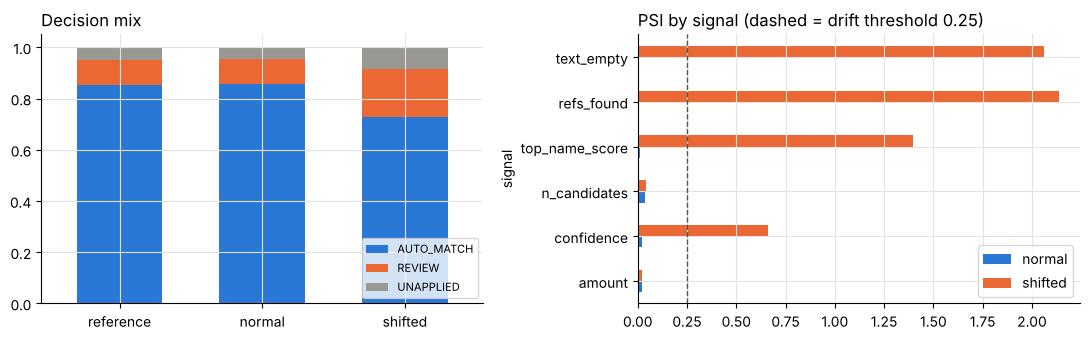

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
mix = pd.DataFrame({m: reports[m]["mix"]["current"] for m in reports}); mix.insert(0, "reference", reports["normal"]["mix"]["reference"])
mix.T.plot.bar(stacked=True, ax=axes[0], color=[BLUE, ORANGE, "#9a9893"], width=0.6, rot=0)
axes[0].set_title("Decision mix", loc="left"); axes[0].legend(loc="lower right", fontsize=8)
d = pd.DataFrame({m: reports[m]["drift"].set_index("signal").psi for m in reports}).drop("decision")
d.plot.barh(ax=axes[1], color=[BLUE, ORANGE]); axes[1].axvline(0.25, color=MUTED, ls="--", lw=1)
axes[1].set_title("PSI by signal (dashed = drift threshold 0.25)", loc="left")
plt.tight_layout(); plt.show()

**Reading it:** normal traffic looks like the reference (all PSI < 0.1, auto-match rate ~85 %, audited precision 100 %). After the bank format change the share of payments with no usable reference jumps from ~22 % to ~87 %, confidence drops, and auto-match rate falls ~12 points, so the monitor raises alerts *before* month-end close reveals a pile of unapplied cash. Note that audited precision stays at 100 %: the decision layer degrades safely by sending more to review instead of guessing.

**What to do:** fix or re-map the bank feed first (it's an upstream data issue, not a model issue). If the change is permanent, retrain with the new format so the model learns to lean on name and amount.